<a href="https://colab.research.google.com/github/olblinova/python_for_ds_tasks-is-available/blob/main/%22HW_16_1_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D0%BE%D1%80%D0%B5%D0%BD%D0%B4%D0%BD%D0%BE%D1%97_%D0%BF%D0%BB%D0%B0%D1%82%D0%B8_%D0%B7%D0%B0_%D0%B6%D0%B8%D1%82%D0%BB%D0%BE_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Прогнозування орендної плати за житло

## Мета завдання
Застосувати знання з лекції для побудови моделі лінійної регресії, що прогнозує орендну плату за житло в Індії. Ви пройдете весь цикл вирішення задачі машинного навчання: від дослідницького аналізу до оцінки якості моделі.

## Опис датасету
**House Rent Prediction Dataset** містить інформацію про 4700+ оголошень про оренду житла в Індії з такими параметрами:
- **BHK**: Кількість спалень, залів, кухонь
- **Rent**: Орендна плата (цільова змінна)
- **Size**: Площа в квадратних футах
- **Floor**: Поверх та загальна кількість поверхів
- **Area Type**: Тип розрахунку площі
- **Area Locality**: Район
- **City**: Місто
- **Furnishing Status**: Стан меблювання
- **Tenant Preferred**: Тип орендаря
- **Bathroom**: Кількість ванних кімнат
- **Point of Contact**: Контактна особа

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `House_Rent_Dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (включно з типами даних та кількістю значень)


In [11]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
 #Завантажуємо дані
df = pd.read_csv('/content/drive/MyDrive/data/House_Rent_Dataset.csv')

# Перше знайомство з даними
df.shape

(4746, 12)

In [4]:
df.head(5)

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [7]:
# Загальна інформація про дані
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


## Завдання 2: Дослідницький аналіз даних (EDA) (5 балів)

**Що потрібно зробити:**
1. **Аналіз пропущених значень.** Перевірте наявність і відсоток пропущених значень у кожній колонці
2. **Базова статистика.** Обчисліть базову статистику (середнє, квартилі, стандартне відхилення) для числових змінних.
3. **Аналіз цільової змінної.** Побудуйте гістограму розподілу цільової змінної (Rent)
4. **Робота з викидами.** Знайдіть та видаліть викиди в цільовій змінній (якщо є). Визначити викиди можна будь-яким зрозумілим для вас способом, як варіант - таким, що використовується в побудові box-plot (https://en.wikipedia.org/wiki/Box_plot#Example_with_outliers).
5. **Аналіз категоріальних змінних.** Виведіть кількість унікальних значень для кожної з категоріальних колонок.


In [8]:
# 1. Пропущені значення
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
print(missing)

                   missing_count  missing_percent
Posted On                      0              0.0
BHK                            0              0.0
Rent                           0              0.0
Size                           0              0.0
Floor                          0              0.0
Area Type                      0              0.0
Area Locality                  0              0.0
City                           0              0.0
Furnishing Status              0              0.0
Tenant Preferred               0              0.0
Bathroom                       0              0.0
Point of Contact               0              0.0


Пропусків немає в жодній із 12 колонок (0 %), тож заповнювати або видаляти нічого не треба.

In [9]:
# 2. Базова статистика числових змінних
# describe() дає count, mean, std, min, 25%, 50%, 75%, max
print(df.describe().T)

           count          mean           std     min      25%      50%  \
BHK       4746.0      2.083860      0.832256     1.0      2.0      2.0   
Rent      4746.0  34993.451327  78106.412937  1200.0  10000.0  16000.0   
Size      4746.0    967.490729    634.202328    10.0    550.0    850.0   
Bathroom  4746.0      1.965866      0.884532     1.0      1.0      2.0   

              75%        max  
BHK           3.0        6.0  
Rent      33000.0  3500000.0  
Size       1200.0     8000.0  
Bathroom      2.0       10.0  


Середнє Rent (≈35 тис.) більш ніж удвічі більше за медіану (16 тис.), а std перевищує середнє. Це ознака сильно правосторонньо скошеного розподілу з екстремальними значеннями.
Максимум Rent становить 3,5 млн, тобто в 100 разів більше за середнє. Швидше за все, це помилка в даних або елітна нерухомість.
Мінімальний Size дорівнює 10 кв. футів, що нереально для житла. Це, імовірно, помилка введення.

In [15]:
df[df.Size < 100]

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
116,2022-05-30,1,5000,20,2 out of 3,Super Area,Dakshineswar,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
189,2022-05-24,1,6500,44,Ground out of 1,Carpet Area,Baranagar,Kolkata,Furnished,Bachelors/Family,1,Contact Owner
1661,2022-05-25,1,6900,50,Ground out of 4,Carpet Area,Kodigehalli,Bangalore,Semi-Furnished,Bachelors,1,Contact Owner
2417,2022-05-18,1,20000,75,2 out of 4,Carpet Area,Malviya Nagar,Delhi,Unfurnished,Bachelors/Family,1,Contact Agent
2425,2022-05-31,2,13000,70,1 out of 3,Super Area,Vikaspuri,Delhi,Semi-Furnished,Bachelors/Family,1,Contact Owner
...,...,...,...,...,...,...,...,...,...,...,...,...
4512,2022-05-12,1,5500,67,Ground out of 1,Super Area,Jagadgiri Gutta,Hyderabad,Semi-Furnished,Bachelors/Family,1,Contact Owner
4525,2022-05-12,2,11000,90,Ground out of 5,Super Area,Shaikpet,Hyderabad,Semi-Furnished,Bachelors/Family,2,Contact Owner
4653,2022-06-29,3,15000,10,1 out of 1,Carpet Area,"Ghatkesar, NH 2 2",Hyderabad,Furnished,Bachelors/Family,3,Contact Owner
4706,2022-04-30,1,4500,50,4 out of 5,Super Area,Amberpet,Hyderabad,Unfurnished,Bachelors/Family,1,Contact Owner


In [ ]:
Це підтверджує, що малі значення Size є помилками введення, а не реальним житлом

In [16]:
# розподіл малих значень Size
print(df_clean["Size"].describe())
print((df_clean["Size"] < 100).sum(), (df_clean["Size"] < 150).sum(), (df_clean["Size"] < 200).sum())

# видалення
df_clean = df_clean[df_clean["Size"] >= 100].copy()
print(len(df_clean))

count    4226.000000
mean      871.779224
std       485.779381
min        10.000000
25%       520.000000
50%       800.000000
75%      1100.000000
max      4200.000000
Name: Size, dtype: float64
91 157 195
4135


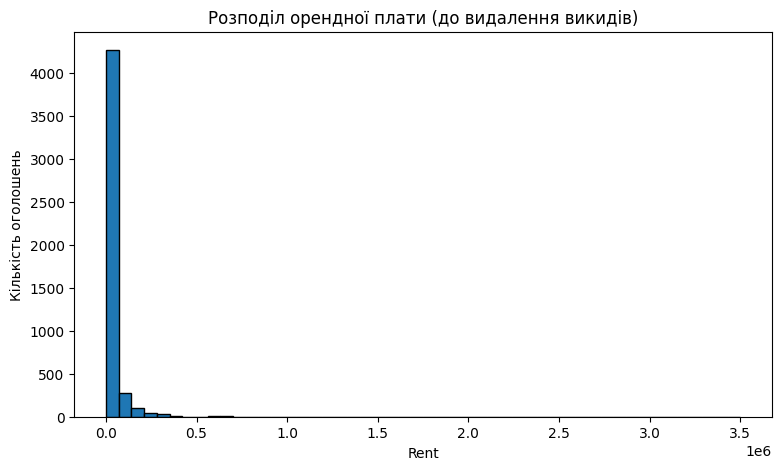

In [17]:
# 3. Розподіл цільової змінної
plt.figure(figsize=(9, 5))
plt.hist(df["Rent"], bins=50, edgecolor="black")
plt.title("Розподіл орендної плати (до видалення викидів)")
plt.xlabel("Rent")
plt.ylabel("Кількість оголошень")
plt.show()

Майже всі оголошення потрапляють у перший стовпчик, а довгий хвіст тягнеться до 3,5 млн. Через цей хвіст розподіл на гістограмі майже не читається

Q1=10000.0, Q3=33000.0, IQR=23000.0
Межі: [-24500.0, 67500.0]
Викидів: 520 (10.96%)
Розмір до: 4746, після: 4226


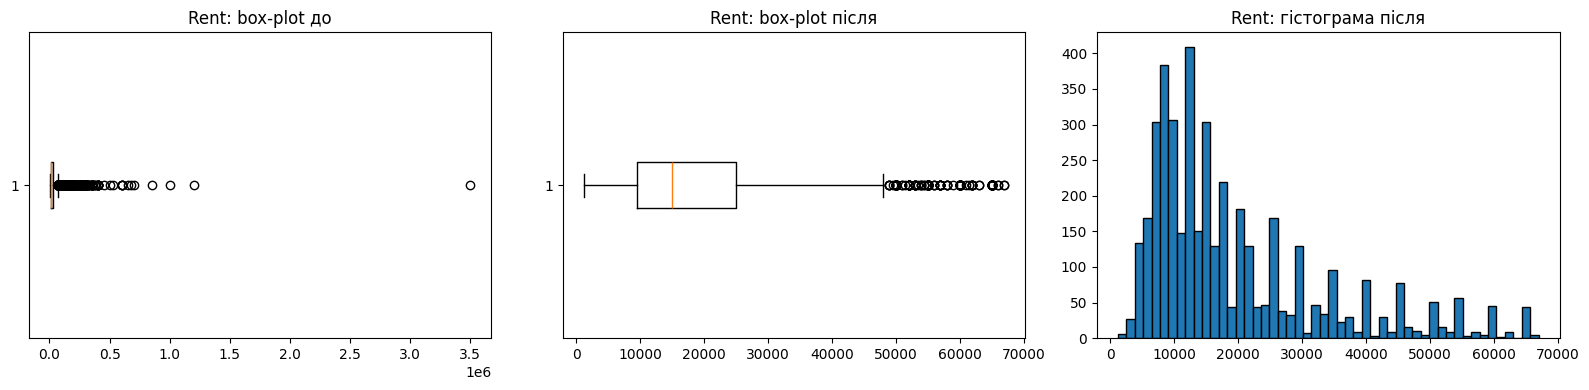

In [18]:
# 4. Викиди (правило IQR, як у box-plot)
Q1 = df["Rent"].quantile(0.25)
Q3 = df["Rent"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print(f"Q1={Q1}, Q3={Q3}, IQR={IQR}")
print(f"Межі: [{lower}, {upper}]")

outliers = df[(df["Rent"] < lower) | (df["Rent"] > upper)]
print(f"Викидів: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)")

df_clean = df[(df["Rent"] >= lower) & (df["Rent"] <= upper)].copy()
print(f"Розмір до: {len(df)}, після: {len(df_clean)}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].boxplot(df["Rent"], vert=False)
axes[0].set_title("Rent: box-plot до")
axes[1].boxplot(df_clean["Rent"], vert=False)
axes[1].set_title("Rent: box-plot після")
axes[2].hist(df_clean["Rent"], bins=50, edgecolor="black")
axes[2].set_title("Rent: гістограма після")
plt.tight_layout()
plt.show()


Після очищення гістограма читається значно краще. Розподіл усе ще скошений праворуч, і на box-plot «після» видно нові «викиди».

In [19]:
# 5. Категоріальні змінні
cat_cols = df_clean.select_dtypes(include="object").columns
print(df_clean[cat_cols].nunique().sort_values(ascending=False))
for c in cat_cols:
    if df_clean[c].nunique() <= 10:
        print(f"\n{c}:\n{df_clean[c].value_counts()}")

Area Locality        1997
Floor                 340
Posted On              80
City                    6
Area Type               3
Furnishing Status       3
Tenant Preferred        3
Point of Contact        3
dtype: int64

Area Type:
Area Type
Super Area     2383
Carpet Area    1841
Built Area        2
Name: count, dtype: int64

City:
City
Bangalore    851
Chennai      850
Hyderabad    845
Mumbai       605
Delhi        552
Kolkata      523
Name: count, dtype: int64

Furnishing Status:
Furnishing Status
Semi-Furnished    1984
Unfurnished       1722
Furnished          520
Name: count, dtype: int64

Tenant Preferred:
Tenant Preferred
Bachelors/Family    3114
Bachelors            729
Family               383
Name: count, dtype: int64

Point of Contact:
Point of Contact
Contact Owner      3168
Contact Agent      1057
Contact Builder       1
Name: count, dtype: int64



## Завдання 3: Аналіз кореляцій та взаємозв'язків (3 бали)

**Що потрібно зробити:**
1. Обчисліть матрицю кореляцій для числових змінних
2. Візуалізуйте кореляційну матрицю за допомогою heatmap
3. Побудуйте scatter plot між Size та Rent
4. Проаналізуйте взаємозв'язок між BHK та Rent за допомогою boxplot (який розподіл плати для різних значень BHK)


            BHK   Rent   Size  Bathroom
BHK       1.000  0.401  0.698     0.748
Rent      0.401  1.000  0.394     0.507
Size      0.698  0.394  1.000     0.681
Bathroom  0.748  0.507  0.681     1.000


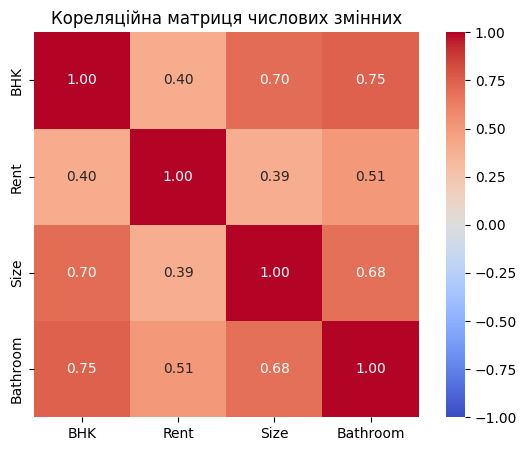

In [23]:
import seaborn as sns

num_cols = ["BHK", "Rent", "Size", "Bathroom"]

# 1. Матриця кореляцій
corr = df_clean[num_cols].corr()
print(corr.round(3))

# 2. Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Кореляційна матриця числових змінних")
plt.show()

Зв'язок із Rent. Усі три ознаки корелюють із цільовою змінною додатно, але помірно: Bathroom 0,51, BHK 0,40, Size 0,39. Сильного лінійного зв'язку немає, тобто жодна ознака окремо не пояснює орендну плату.

Найінформативніша ознака. Bathroom має найвищу кореляцію з Rent. Імовірно, кількість ванних кімнат непрямо відображає клас житла.

Взаємна кореляція ознак. Предиктори сильно пов'язані між собою: BHK–Bathroom 0,75, BHK–Size 0,70, Size–Bathroom 0,68. Це мультиколінеарність: більша квартира має більше кімнат і ванних. Вона не погіршить якість прогнозу, але зробить коефіцієнти лінійної регресії менш стійкими та складними для інтерпретації.

Обмеження. Кореляція Пірсона вимірює лише лінійний зв'язок і чутлива до викидів. Помірні значення частково пояснюються тим, що на ціну сильно впливають нечислові ознаки, передусім City.

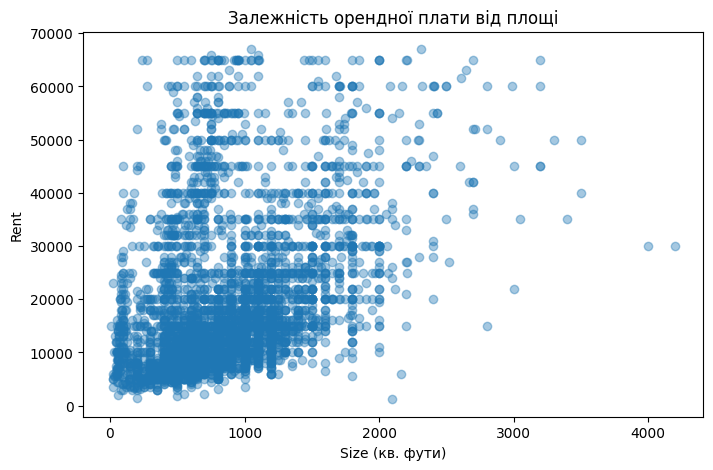

In [24]:
# 3. Scatter plot: Size vs Rent
plt.figure(figsize=(8, 5))
plt.scatter(df_clean["Size"], df_clean["Rent"], alpha=0.4)
plt.xlabel("Size (кв. фути)")
plt.ylabel("Rent")
plt.title("Залежність орендної плати від площі")
plt.show()

Загальна тенденція. Зв'язок є, але слабкий: хмара точок піднімається вправо, при цьому розкид дуже великий. Квартири площею близько 1000 кв. футів мають Rent від 5 000 до 65 000.

Розкид Rent зростає зі збільшенням Size, що порушує одну з припущень лінійної регресії.

Горизонтальні смуги. Це наслідок того, що орендодавці називають «круглі» суми (10 000, 15 000, 20 000 тощо).

Верхня межа. Різка стеля на рівні ≈65 000 є результатом нашого видалення викидів за IQR, а не властивістю ринку.

Викиди за Size. Праворуч видно кілька точок із площею 3000–4000 кв. футів і Rent близько 30 000. Вони виглядають підозріло, а зліва, біля нуля, видно залишки помилкових значень Size.

Вплив міста. Розкид при однаковій площі добре пояснюється містом, тому ознаку City треба включити в модель.

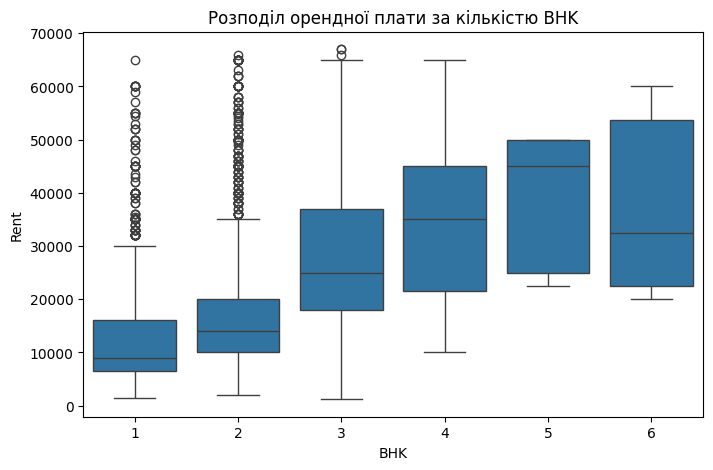

     count   median     mean
BHK                         
1     1156   9000.0  13413.0
2     2165  14000.0  18141.0
3      838  25000.0  29014.0
4       56  35000.0  35561.0
5        5  45000.0  38500.0
6        6  32500.0  37500.0


In [25]:
# 4. Boxplot: Rent для різних BHK
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="BHK", y="Rent")
plt.title("Розподіл орендної плати за кількістю BHK")
plt.show()

# допоміжно: медіана і кількість записів по BHK
print(df_clean.groupby("BHK")["Rent"].agg(["count", "median", "mean"]).round(0))

Bисновки: Орендна плата має помірний додатний лінійний зв'язок із Bathroom, BHK і Size, а ці ознаки сильно корельовані між собою. Слабкість лінійного зв'язку та великий розкид вказують, що без категоріальних ознак (насамперед City) якість моделі буде обмеженою. Також варто розглянути логарифмування Rent і обмеження Size з обох боків.

## Завдання 4: Feature Engineering та підготовка даних (4 бали)

**Що потрібно зробити:**
1. Закодуйте категоріальні змінні за допомогою One-Hot Encoding. Пригадайте, що в лекції ми говорили щодо кодування кат. змінних з великої кількістю різних значень і як працювати з такими випадками. Ви можете закодувати не всі кат. змінні, а лише ті, що вважаєте за потрібні (скажімо ті, що мають відносно небагато різних значень).
2. **Опціонально (по 0.5 бала за кожну доцільну ознаку):** Додайте нові ознаки, обчислені на основі наявних даних, які б на ваш погляд були корисними для моделі
3. Виберіть ознаки для побудови моделі (виключіть непотрібні колонки). Виключити можна, наприклад, ті колонки, які мають категоріальний тип і забагато (більше 20) різних значень. Треба виключити хоча б 1 колонку.
4. Розділіть дані на ознаки (X) та цільову змінну (y)
5. Застосуйте стандартизацію до числових ознак


In [29]:
from sklearn.preprocessing import StandardScaler

data = df_clean.copy()

# ---------- Видалення нереальних значень площі ----------
before = len(data)
data = data[data["Size"] >= 100].copy()
print(f"Видалено через малий Size: {before - len(data)}")

# ---------- Розбір Floor ----------
def parse_floor(s):
    s = str(s).strip()
    parts = s.split(" out of ")
    cur = parts[0].strip().lower()
    total = float(parts[1]) if len(parts) > 1 and parts[1].strip().isdigit() else np.nan
    if cur == "ground":
        floor = 0
    elif "lower basement" in cur:
        floor = -2
    elif "upper basement" in cur:
        floor = -1
    elif cur.isdigit():
        floor = int(cur)
    else:
        floor = np.nan
    return pd.Series([floor, total])

data[["Floor_num", "Total_floors"]] = data["Floor"].apply(parse_floor)
print(data[["Floor_num", "Total_floors"]].isna().sum())

data["Floor_num"] = data["Floor_num"].fillna(data["Floor_num"].median())
data["Total_floors"] = data["Total_floors"].fillna(data["Total_floors"].median())

# ---------- Нові ознаки ----------
data["Floor_ratio"] = data["Floor_num"] / data["Total_floors"].clip(lower=1)
data["Size_per_BHK"] = data["Size"] / data["BHK"]
data["Bath_per_BHK"] = data["Bathroom"] / data["BHK"]

# ---------- Рідкісні категорії ----------
data = data[(data["Area Type"] != "Built Area") &
            (data["Point of Contact"] != "Contact Builder")].copy()

# ---------- Виключення колонок ----------
# Area Locality: 1997 унікальних значень; Floor: замінений на числові ознаки;
# Posted On: усі дати з одного короткого періоду
data = data.drop(columns=["Area Locality", "Floor", "Posted On"])

# ---------- One-Hot Encoding ----------
cat_cols = ["Area Type", "City", "Furnishing Status", "Tenant Preferred", "Point of Contact"]
data = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=float)

# ---------- X та y ----------
y = data["Rent"]
X = data.drop(columns=["Rent"]).astype(float)
print(X.shape, y.shape)
print(X.columns.tolist())
print("Пропусків у X:", X.isna().sum().sum())

# ---------- Стандартизація числових ознак ----------
num_cols = ["BHK", "Size", "Bathroom", "Floor_num", "Total_floors",
            "Floor_ratio", "Size_per_BHK", "Bath_per_BHK"]

scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[num_cols] = scaler.fit_transform(X[num_cols])

print(X_scaled[num_cols].describe().loc[["mean", "std"]].round(3))
X_scaled.head()

Видалено через малий Size: 91
Floor_num       0
Total_floors    4
dtype: int64
(4132, 19) (4132,)
['BHK', 'Size', 'Bathroom', 'Floor_num', 'Total_floors', 'Floor_ratio', 'Size_per_BHK', 'Bath_per_BHK', 'Area Type_Super Area', 'City_Chennai', 'City_Delhi', 'City_Hyderabad', 'City_Kolkata', 'City_Mumbai', 'Furnishing Status_Semi-Furnished', 'Furnishing Status_Unfurnished', 'Tenant Preferred_Bachelors/Family', 'Tenant Preferred_Family', 'Point of Contact_Contact Owner']
Пропусків у X: 0
      BHK  Size  Bathroom  Floor_num  Total_floors  Floor_ratio  Size_per_BHK  \
mean  0.0  -0.0      -0.0        0.0          -0.0          0.0           0.0   
std   1.0   1.0       1.0        1.0           1.0          1.0           1.0   

      Bath_per_BHK  
mean           0.0  
std            1.0  


,BHK,Size,Bathroom,Floor_num,Total_floors,Floor_ratio,Size_per_BHK,Bath_per_BHK,Area Type_Super Area,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner
0,0.045578,0.441793,0.260889,-0.705200,-0.547512,-1.323758,0.583082,0.140794,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0
1,0.045578,-0.188554,-1.142747,-0.430952,-0.389296,-0.330927,-0.338703,-1.641195,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
2,0.045578,0.231678,-1.142747,-0.430952,-0.389296,-0.330927,0.275820,-1.641195,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
3,0.045578,-0.188554,-1.142747,-0.430952,-0.547512,0.165488,-0.338703,-1.641195,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0
4,0.045578,-0.083496,-1.142747,-0.430952,-0.547512,0.165488,-0.185072,-1.641195,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0


Закодовано п'ять категоріальних колонок із 3–6 значеннями (One-Hot, drop_first=True).

Area Locality (1997 значень) виключено, щоб не створювати майже 2000 колонок.
Виключено колонки Area Locality, Floor (замінено на числові ознаки) і Posted On (усі дати з одного короткого періоду).

Додано нові ознаки: Floor_num, Total_floors, Floor_ratio, Size_per_BHK і Bath_per_BHK.

Видалено 91 запис із нереальною площею (менше 100 кв. футів) і 3 записи з рідкісних категорій (Built Area, Contact Builder).

Дані розділено на X та y, числові ознаки стандартизовано.

## Завдання 5: Розділення даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на навчальну (80%) та тестову (20%) вибірки.
2. Створіть модель лінійної регресії.
3. Навчіть модель на навчальних даних.
4. Виведіть усі коефіцієнти моделі (ваги) та напишіть, які 2 ознаки найбільше впливають на прогноз.
5. Зробіть прогнози на тренувальній та тестовій вибірках.

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Розділення 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

# Стандартизація: fit лише на train
num_cols = ["BHK", "Size", "Bathroom", "Floor_num", "Total_floors",
            "Floor_ratio", "Size_per_BHK", "Bath_per_BHK"]

scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# 2-3. Модель та навчання
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Коефіцієнти
coef = pd.Series(model.coef_, index=X_train.columns)
print("Intercept:", round(model.intercept_, 2))
print(coef.sort_values(key=abs, ascending=False).round(2))

print("\nТоп-2 за модулем:")
print(coef.abs().sort_values(ascending=False).head(2))

# 5. Прогнози
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print(pd.DataFrame({"y_test": y_test.values[:5],
                    "y_pred": y_test_pred[:5].round(0)}))

(3305, 19) (827, 19)
Intercept: 27769.83
City_Mumbai                          17341.91
Point of Contact_Contact Owner       -7645.59
Bathroom                              4269.57
Furnishing Status_Unfurnished        -4034.28
Tenant Preferred_Family              -3162.57
Size                                  3004.64
Furnishing Status_Semi-Furnished     -2976.72
City_Kolkata                         -2916.30
City_Hyderabad                       -2701.02
City_Delhi                            2040.63
Total_floors                          1882.41
Bath_per_BHK                         -1862.51
Tenant Preferred_Bachelors/Family    -1025.06
City_Chennai                          -961.30
BHK                                    565.29
Size_per_BHK                           517.10
Area Type_Super Area                  -174.86
Floor_num                             -131.31
Floor_ratio                            107.27
dtype: float64

Топ-2 за модулем:
City_Mumbai                       17341.912441
Poin

Коефіцієнти виглядають логічно. Дві ознаки з найбільшим впливом (за модулем коефіцієнта):

1. City_Mumbai (+17 342). За інших однакових умов оренда в Мумбаї приблизно на 17 тис. вища, ніж у Бангалорі. Ця категорія є базовою, бо після drop_first=True колонки City_Bangalore немає. Цей вплив значно більший за решту.
2. Point of Contact_Contact Owner (−7 646). Оголошення від власника в середньому на 7,6 тис. дешевші, ніж оголошення від агента (базова категорія Contact Agent). Це можна пояснити комісією та націнкою агентів, але модель показує лише зв'язок, а не причину.

Серед числових ознак найсильніше впливають Bathroom (+4 270) і Size (+3 005). Це узгоджується з кореляціями.

## Завдання 6: Оцінка якості моделі (2 бали)

**Що потрібно зробити:**
1. Обчисліть MAE, RMSE та R² для навчальної та тестової вибірок
2. Порівняйте метрики та зробіть висновок про якість моделі
3. Проаналізуйте і дайте висновок, чи є ознаки перенавчання або недонавчання (**Нагадування**: перенавчання - коли модель дуже добре працює на тренувальних даних, але погано на тестових; недонавчання - коли модель погано працює навіть на тренувальних даних)
4. Побудуйте графік розсіювання "реальні vs прогнозовані значення" та зробіть висновок про якість моделі


            MAE      RMSE     R2
train  5438.745  7569.088  0.707
test   5446.075  7625.569  0.681

Середнє Rent (train): 19580
Медіана Rent (train): 15000
MAE базової моделі (середнє): 10525


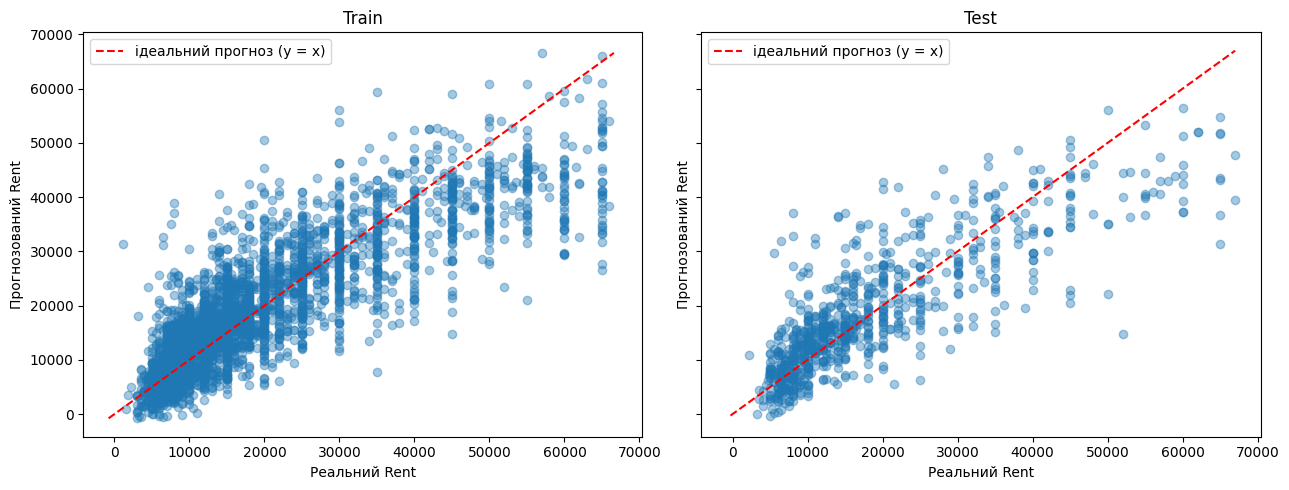

Від'ємних прогнозів (test): 1


In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Метрики
def metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

res = pd.DataFrame({
    "train": metrics(y_train, y_train_pred),
    "test": metrics(y_test, y_test_pred),
}).T
print(res.round(3))

# для контексту: масштаб цільової змінної та базова модель (прогноз = середнє)
print("\nСереднє Rent (train):", round(y_train.mean()))
print("Медіана Rent (train):", round(y_train.median()))
print("MAE базової моделі (середнє):",
      round(mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))))

# 4. Реальні vs прогнозовані
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, yt, yp, title in [(axes[0], y_train, y_train_pred, "Train"),
                          (axes[1], y_test, y_test_pred, "Test")]:
    ax.scatter(yt, yp, alpha=0.4)
    lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
    ax.plot(lims, lims, "r--", label="ідеальний прогноз (y = x)")
    ax.set_xlabel("Реальний Rent")
    ax.set_ylabel("Прогнозований Rent")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

# додатково: від'ємні прогнози
print("Від'ємних прогнозів (test):", (y_test_pred < 0).sum())

Модель має прийнятну якість (R² ≈ 0,68, MAE ≈ 5,4 тис., удвічі краще за базовий прогноз середнім) і не перенавчена. Основні обмеження: лінійність, відсутність інформації про район та скошена цільова змінна.

## Завдання 7: Аналіз помилок (4 бали)

**Що потрібно зробити:**
1. Обчисліть помилки (residuals = реальні - прогнозовані значення)
2. Побудуйте гістограму розподілу помилок
3. Створіть scatter plot помилок відносно величини прогнозованих значень. Чи росте помилка з ростом прогнозованого значення?
4. Знайдіть 5 прогнозів з найбільшими помилками
5. Проаналізуйте, на яких типах житла модель помиляється найбільше. Типи можна розрізняти за кількістю кімнат чи містом, наприклад.
6. Подумайте і напишіть, які наступні кроки ви б зробили, аби поліпшити якість моделі. Опціонально можна їх зробити і ми перевіримо :)

In [32]:
# 1. Помилки
res_train = y_train - y_train_pred
res_test = y_test - y_test_pred          # індекс збережено
print("Середня помилка (test):", round(res_test.mean(), 1))
print("Std помилки (test):", round(res_test.std(), 1))


Середня помилка (test): -78.5
Std помилки (test): 7629.8


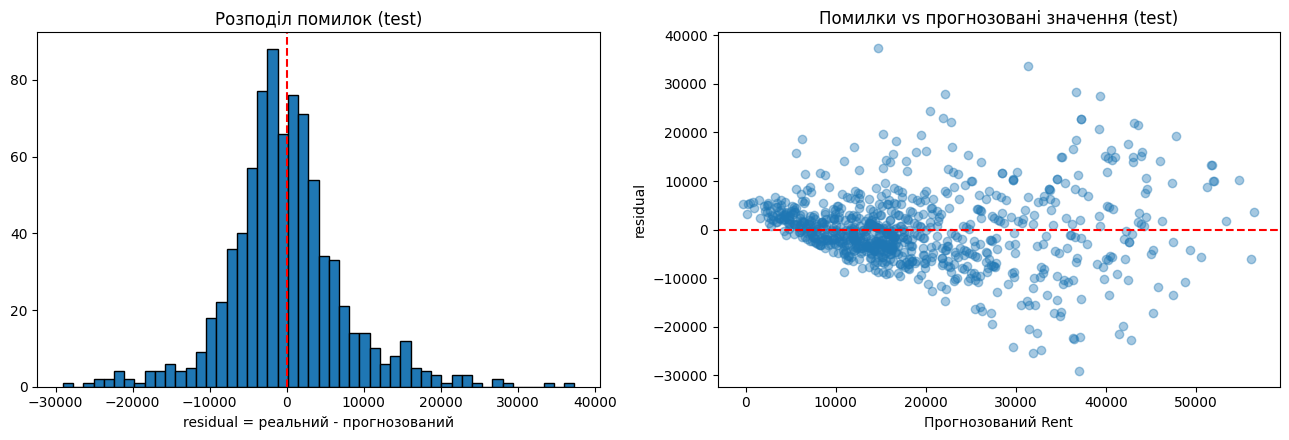

                                 count    mean      std
(-283.58599999999996, 9557.823]    166  2106.0   3461.0
(9557.823, 14227.771]              165  -559.0   3989.0
(14227.771, 18321.841]             165  -727.0   6245.0
(18321.841, 28344.85]              165 -1382.0   8314.0
(28344.85, 56477.43]               166   154.0  12205.0
corr(|residual|, прогноз): 0.458


/tmp/ipykernel_4192/394389014.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(res_test.groupby(bins).agg(["count", "mean", "std"]).round(0))


In [34]:
# 2. Гістограма помилок
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(res_test, bins=50, edgecolor="black")
axes[0].axvline(0, color="r", linestyle="--")
axes[0].set_title("Розподіл помилок (test)")
axes[0].set_xlabel("residual = реальний - прогнозований")

# 3. Помилки vs прогноз
axes[1].scatter(y_test_pred, res_test, alpha=0.4)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_title("Помилки vs прогнозовані значення (test)")
axes[1].set_xlabel("Прогнозований Rent")
axes[1].set_ylabel("residual")
plt.tight_layout()
plt.show()

# чи росте розкид помилок із прогнозом?
bins = pd.qcut(pd.Series(y_test_pred, index=y_test.index), 5)
print(res_test.groupby(bins).agg(["count", "mean", "std"]).round(0))
print("corr(|residual|, прогноз):",
      round(np.corrcoef(np.abs(res_test), y_test_pred)[0, 1], 3))


In [35]:
# 4. Топ-5 найбільших помилок
info = df_clean.loc[y_test.index, ["City", "BHK", "Size", "Bathroom",
                                   "Furnishing Status", "Area Locality"]].copy()
info["Rent"] = y_test
info["pred"] = y_test_pred.round(0)
info["residual"] = res_test.round(0)
info["abs_err"] = res_test.abs().round(0)
print(info.sort_values("abs_err", ascending=False).head(5))

           City  BHK  Size  Bathroom Furnishing Status  \
2965      Delhi    3   200         2       Unfurnished   
3962  Hyderabad    3  1850         3         Furnished   
1150     Mumbai    2   623         2       Unfurnished   
2707      Delhi    3  1600         2         Furnished   
181     Kolkata    1  2200         3         Furnished   

                     Area Locality   Rent     pred  residual  abs_err  
2965             South Extension 1  52000  14693.0   37307.0  37307.0  
3962    Patrika Nagar, Hitech City  65000  31293.0   33707.0  33707.0  
1150  Shreenath nagar, Morya Nagar   8000  37042.0  -29042.0  29042.0  
2707               East Of Kailash  65000  36712.0   28288.0  28288.0  
181                    Kanchrapara  50000  22108.0   27892.0  27892.0  


In [36]:
# 5. Де модель помиляється найбільше
info["rel_err_%"] = info["abs_err"] / info["Rent"] * 100

def summary(col):
    return (info.groupby(col)
                .agg(n=("Rent", "size"),
                     MAE=("abs_err", "mean"),
                     bias=("residual", "mean"),        # >0: модель занижує
                     rel_err=("rel_err_%", "mean"))
                .round(1))

print(summary("City"))
print(summary("BHK"))
print(summary("Furnishing Status"))

             n      MAE    bias  rel_err
City                                    
Bangalore  172   3769.3  -262.1     27.1
Chennai    154   4460.1  -177.3     30.8
Delhi       98   6498.9  1368.0     35.5
Hyderabad  160   5086.3  1101.6     33.1
Kolkata    126   4272.9    45.7     44.0
Mumbai     117  10082.5 -2637.4     50.3
       n     MAE    bias  rel_err
BHK                              
1    221  5045.2    36.4     44.4
2    441  4735.0  -835.5     33.3
3    158  7912.2  2027.4     30.9
4      6  7561.3 -5015.0     33.3
5      1  5283.0  5283.0     23.5
                     n     MAE    bias  rel_err
Furnishing Status                              
Furnished          101  7900.0  2425.3     38.0
Semi-Furnished     382  5264.2  -141.7     31.9
Unfurnished        344  4927.6  -743.3     39.5


Помилки моделі мають майже нормальний розподіл із центром біля нуля (середня помилка на тесті −78,5, std 7630). Систематичного зсуву в цілому немає, але точність нерівномірна: модель добре працює для дешевого та середнього житла і помітно гірше для дорогого.
Розподіл і залежність від прогнозу. На гістограмі видно трохи важчий правий хвіст, тобто модель частіше сильно занижує дорогі квартири, ніж завищує дешеві. Помилка явно зростає з ростом прогнозованого значення: std помилки збільшується з 3,5 тис. у нижньому квантилі прогнозу до 12,2 тис. у верхньому, а кореляція |residual| із прогнозом дорівнює 0,46.
П'ять найбільших помилок: чотири з п'яти є занижениями дорогого житла, а одна завищенням.

Загальна закономірність: модель гірше за все прогнозує дорогі квартири та міста з великою різницею між районами (Mumbai, Delhi). Це пояснюється тим, що модель не знає району й не може описати нелінійні залежності та різну ціну квадратного фута.

Наступні кроки

Логарифмування цільової змінної (log1p(Rent)).
Інформація про район. Target encoding для Area Locality (out-of-fold, лише на train, зі згладжуванням). Це найімовірніше вирішить проблему з Mumbai і Delhi.
Взаємодії ознак, передусім Size × City, бо вартість квадратного фута різна в різних містах.
Очищення даних. Видалити явні аномалії за співвідношенням площі та кількості кімнат (наприклад, Size_per_BHK менше ≈ 80 або понад ≈ 1500).

In [37]:
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

loc_train = df_clean.loc[X_train.index, "Area Locality"]
loc_test = df_clean.loc[X_test.index, "Area Locality"]

global_mean = y_train.mean()
smooth = 10   # чим більше, тим сильніше рідкісні райони тягнуться до середнього

def fit_map(locs, target):
    g = target.groupby(locs).agg(["sum", "count"])
    return (g["sum"] + smooth * global_mean) / (g["count"] + smooth)

# train: out-of-fold, щоб рядок не бачив власного Rent
te_train = pd.Series(index=X_train.index, dtype=float)
for tr_idx, va_idx in KFold(5, shuffle=True, random_state=42).split(X_train):
    mp = fit_map(loc_train.iloc[tr_idx], y_train.iloc[tr_idx])
    te_train.iloc[va_idx] = loc_train.iloc[va_idx].map(mp).fillna(global_mean).values

# test: мапа з усього train, невідомі райони отримують глобальне середнє
te_test = loc_test.map(fit_map(loc_train, y_train)).fillna(global_mean)

X_train2 = X_train.copy(); X_test2 = X_test.copy()
X_train2["Locality_TE"] = te_train
X_test2["Locality_TE"] = te_test

sc = StandardScaler()
X_train2[["Locality_TE"]] = sc.fit_transform(X_train2[["Locality_TE"]])
X_test2[["Locality_TE"]] = sc.transform(X_test2[["Locality_TE"]])

model2 = LinearRegression().fit(X_train2, y_train)
pred2 = model2.predict(X_test2)

def rep(name, yt, yp):
    return {"model": name,
            "MAE": mean_absolute_error(yt, yp),
            "RMSE": np.sqrt(mean_squared_error(yt, yp)),
            "R2": r2_score(yt, yp)}

print(pd.DataFrame([rep("Базова", y_test, y_test_pred),
                    rep("+ район (TE)", y_test, pred2)]).set_index("model").round(3))

# Чи покращилось по містах?
res2 = y_test - pred2
by_city = (pd.DataFrame({"City": df_clean.loc[y_test.index, "City"],
                         "MAE_old": (y_test - y_test_pred).abs(),
                         "MAE_new": res2.abs()})
           .groupby("City").mean().round(0))
print(by_city)

# Коефіцієнт нової ознаки
print("Коефіцієнт Locality_TE:", round(model2.coef_[list(X_train2.columns).index("Locality_TE")], 0))

                   MAE      RMSE     R2
model                                  
Базова        5446.075  7625.569  0.681
+ район (TE)  5355.608  7537.149  0.689
           MAE_old  MAE_new
City                       
Bangalore   3769.0   3697.0
Chennai     4460.0   4464.0
Delhi       6499.0   6300.0
Hyderabad   5086.0   4760.0
Kolkata     4273.0   4391.0
Mumbai     10082.0  10031.0
Коефіцієнт Locality_TE: 2332.0


додавання інформації про район дало невелике покращення (MAE −1,7 %, R² +0,008) переважно за рахунок Hyderabad і Delhi, а для Мумбаї ефекту практично немає. Це свідчить, що для лінійної моделі ознака району має обмежену користь через велику кількість рідкісних районів. Отже, пріоритетні подальші кроки: кращі способи кодування району та нелінійні моделі.